# Multinomial Logistic Regression: Student Math Performance Category

This notebook predicts a student's **math performance category** (Low / Medium / High) from demographic information, test preparation, and reading and writing scores, using multinomial (softmax) logistic regression.

**Target construction:** `math score` is binned into

| Category | Math score |
|---|---|
| Low | 0 – 60 |
| Medium | 61 – 80 |
| High | 81 – 100 |

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             f1_score, roc_curve, auc, roc_auc_score)

## 2. Load and Inspect Data

In [2]:
df = pd.read_csv('StudentsPerformance.csv')
df.columns = df.columns.str.replace(' ', '_').str.replace('/', '_').str.lower()
df.info()
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Duplicate rows: 0


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 3. Target Variable

In [3]:
class_names = ['Low', 'Medium', 'High']
df['math_category'] = pd.cut(df['math_score'], bins=[0, 60, 80, 100],
                             labels=class_names, include_lowest=True)

# Integer codes in ordinal order: Low = 0, Medium = 1, High = 2
df['math_class'] = df['math_category'].cat.codes
print(df['math_category'].value_counts().reindex(class_names))

math_category
Low       339
Medium    485
High      176
Name: count, dtype: int64


The classes are imbalanced (High is the smallest), so the train/test split and cross-validation folds are **stratified**, and macro-averaged F1 is reported alongside accuracy.

## 4. Exploratory Data Analysis

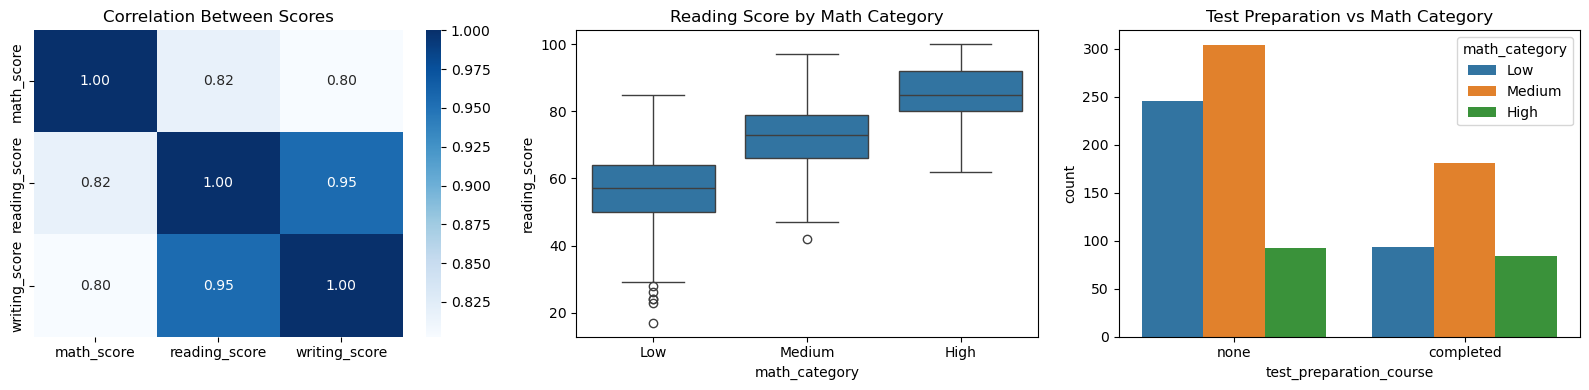

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.heatmap(df[['math_score', 'reading_score', 'writing_score']].corr(), annot=True, fmt='.2f',
            cmap='Blues', ax=axes[0])
axes[0].set_title('Correlation Between Scores')
sns.boxplot(data=df, x='math_category', y='reading_score', order=class_names, ax=axes[1])
axes[1].set_title('Reading Score by Math Category')
sns.countplot(data=df, x='test_preparation_course', hue='math_category', hue_order=class_names, ax=axes[2])
axes[2].set_title('Test Preparation vs Math Category')
plt.tight_layout()
plt.show()

Reading and writing scores are strongly correlated with the math score (r ≈ 0.80). They are legitimate predictors, since they are separate exams and not derived from the math score, but they will dominate the model. Section 7 measures how much of the performance comes from them.

## 5. Preprocessing Pipeline

* **Categorical features** (gender, race/ethnicity, parental education, lunch, test preparation) are **one-hot encoded**. Label encoding would impose a false numeric order on nominal categories such as ethnic group, which a linear model would then treat as meaningful.
* **Numeric features** (reading and writing scores) are **standardized**.

All preprocessing is fitted inside the pipeline on training data only.

In [5]:
categorical_features = ['gender', 'race_ethnicity', 'parental_level_of_education',
                        'lunch', 'test_preparation_course']
numeric_features = ['reading_score', 'writing_score']

X = df[categorical_features + numeric_features]
y = df['math_class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

def make_model(cat_cols, num_cols):
    prep = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
        ('num', StandardScaler(), num_cols),
    ])
    return Pipeline([('prep', prep), ('logreg', LogisticRegression(max_iter=1000))])

model = make_model(categorical_features, numeric_features)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (800, 7)  Test: (200, 7)


## 6. Model Training and Evaluation

### 6.1 Cross-Validation (Training Set)

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_res = cross_validate(model, X_train, y_train, cv=cv,
                        scoring=['accuracy', 'f1_macro', 'roc_auc_ovr'])
print(f"CV Accuracy     : {cv_res['test_accuracy'].mean():.4f} ± {cv_res['test_accuracy'].std():.4f}")
print(f"CV Macro F1     : {cv_res['test_f1_macro'].mean():.4f} ± {cv_res['test_f1_macro'].std():.4f}")
print(f"CV ROC AUC (OvR): {cv_res['test_roc_auc_ovr'].mean():.4f} ± {cv_res['test_roc_auc_ovr'].std():.4f}")

CV Accuracy     : 0.8225 ± 0.0215
CV Macro F1     : 0.8195 ± 0.0250
CV ROC AUC (OvR): 0.9422 ± 0.0105


### 6.2 Hold-out Test Set

In [7]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print(f"Test Accuracy     : {accuracy_score(y_test, y_pred):.4f}")
print(f"Test Macro F1     : {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Test Weighted F1  : {f1_score(y_test, y_pred, average='weighted'):.4f}")
print(f"Test ROC AUC (OvR): {roc_auc_score(y_test, y_proba, multi_class='ovr'):.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Test Accuracy     : 0.8100
Test Macro F1     : 0.8125
Test Weighted F1  : 0.8096
Test ROC AUC (OvR): 0.9530

Classification Report:

              precision    recall  f1-score   support

         Low     0.7945    0.8529    0.8227        68
      Medium     0.8242    0.7732    0.7979        97
        High     0.8056    0.8286    0.8169        35

    accuracy                         0.8100       200
   macro avg     0.8081    0.8182    0.8125       200
weighted avg     0.8108    0.8100    0.8096       200



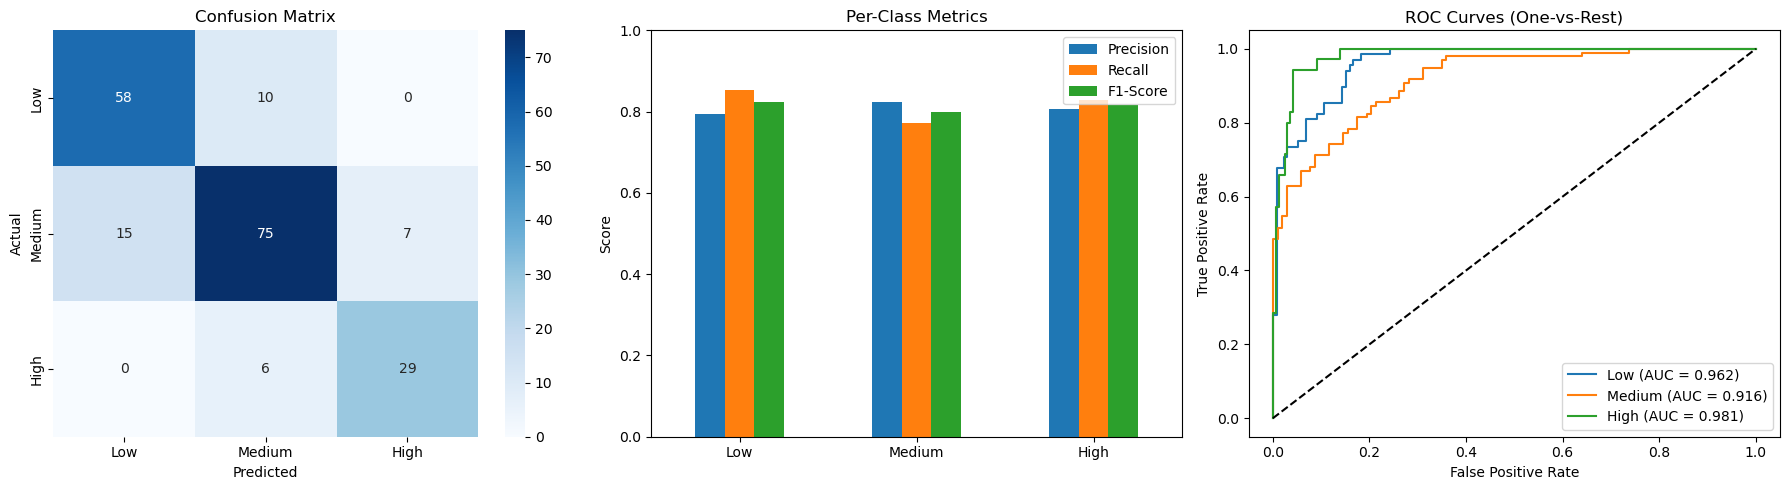

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_title('Confusion Matrix')

# Per-class precision / recall / F1
report = classification_report(y_test, y_pred, target_names=class_names, output_dict=True)
metric_df = pd.DataFrame({c: [report[c]['precision'], report[c]['recall'], report[c]['f1-score']]
                          for c in class_names}, index=['Precision', 'Recall', 'F1-Score']).T
metric_df.plot(kind='bar', ax=axes[1], rot=0)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel('Score')
axes[1].set_title('Per-Class Metrics')

# One-vs-rest ROC curves
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
for i, cls in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    axes[2].plot(fpr, tpr, label=f"{cls} (AUC = {auc(fpr, tpr):.3f})")
axes[2].plot([0, 1], [0, 1], 'k--')
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].set_title('ROC Curves (One-vs-Rest)')
axes[2].legend()

plt.tight_layout()
plt.show()

Errors occur almost only between **adjacent** categories (Low↔Medium, Medium↔High). A Low student is essentially never predicted as High, which fits the ordinal nature of the target.

### 6.3 Coefficients

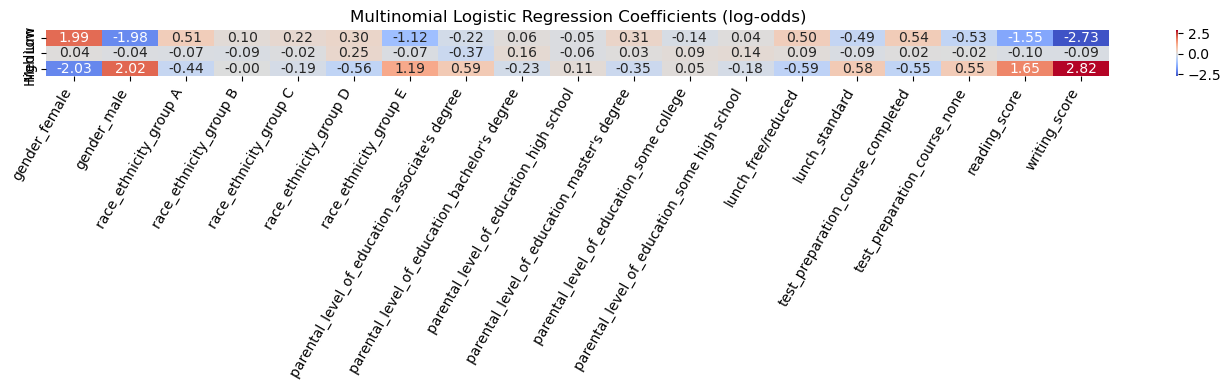

In [9]:
feature_names = model.named_steps['prep'].get_feature_names_out()
feature_names = [f.split('__', 1)[1] for f in feature_names]
coef_df = pd.DataFrame(model.named_steps['logreg'].coef_, index=class_names, columns=feature_names)

plt.figure(figsize=(14, 4))
sns.heatmap(coef_df, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Multinomial Logistic Regression Coefficients (log-odds)')
plt.xticks(rotation=60, ha='right')
plt.tight_layout()
plt.show()

## 7. How Much Comes from Reading and Writing Scores?

The same model is refit **without** the reading and writing scores, using demographic and preparation features only.

In [10]:
model_demo = make_model(categorical_features, [])
cv_demo = cross_validate(model_demo, X_train[categorical_features], y_train, cv=cv,
                         scoring=['accuracy', 'f1_macro'])
model_demo.fit(X_train[categorical_features], y_train)
y_pred_demo = model_demo.predict(X_test[categorical_features])

majority_acc = (y_test == y_train.mode()[0]).mean()
comparison = pd.DataFrame({
    'Model': ['Majority-class baseline', 'Demographics only', 'Demographics + reading/writing'],
    'CV Accuracy': [np.nan, cv_demo['test_accuracy'].mean(), cv_res['test_accuracy'].mean()],
    'Test Accuracy': [majority_acc, accuracy_score(y_test, y_pred_demo), accuracy_score(y_test, y_pred)],
    'Test Macro F1': [np.nan, f1_score(y_test, y_pred_demo, average='macro'), f1_score(y_test, y_pred, average='macro')],
})
print(comparison.round(4).to_string(index=False))

                         Model  CV Accuracy  Test Accuracy  Test Macro F1
       Majority-class baseline          NaN          0.485            NaN
             Demographics only       0.5275          0.495         0.4396
Demographics + reading/writing       0.8225          0.810         0.8125


## 8. Conclusion

| Metric | 5-fold CV (train) | Hold-out test |
|---|---|---|
| Accuracy | 0.823 | 0.810 |
| Macro F1 | 0.820 | 0.813 |
| ROC AUC (one-vs-rest) | 0.942 | 0.953 |

* **Performance:** the multinomial logistic regression classifies math performance into Low / Medium / High with about **81% accuracy**. Recall is balanced across all three classes (0.77 – 0.85).
* **Error pattern:** mistakes occur only between neighboring categories; Low is never confused with High.
* **What drives the predictions:** almost all of the predictive power comes from **reading and writing scores**. Demographics and test preparation alone reach only about 50% accuracy, close to the 48.5% majority-class baseline.
* **Preprocessing fixes compared with the earlier version:**
  * Nominal features are one-hot encoded instead of label encoded.
  * Numeric features are scaled.
  * The split and CV are stratified.
  * Classes are ordered Low < Medium < High.